In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
capital_project = pd.read_csv('aaus5_class_capital_project_finance - aaus5_class_capital_project_finance.csv',parse_dates=['reporting_month'])
fleet_trip_log = pd.read_csv('aaus5_class_fleet_trip_log - aaus5_class_fleet_trip_log.csv',parse_dates=['trip_date'])
inventory_movment = pd.read_csv('aaus5_class_inventory_movements - aaus5_class_inventory_movements.csv' , parse_dates=['event_date'])
montly_kpi = pd.read_csv('aaus5_class_monthly_kpis_wide - aaus5_class_monthly_kpis_wide.csv',parse_dates=['month'])

In [17]:
#capital_project.info()
#fleet_trip_log.info()
inventory_movment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   transaction_id   720 non-null    object        
 1   event_date       720 non-null    datetime64[ns]
 2   warehouse        720 non-null    object        
 3   branch           720 non-null    object        
 4   material_family  720 non-null    object        
 5   sku              720 non-null    object        
 6   event_type       720 non-null    object        
 7   qty_units        720 non-null    int64         
 8   signed_units     720 non-null    int64         
 9   unit_cost_etb    720 non-null    int64         
 10  line_value_etb   720 non-null    int64         
 11  supplier_group   720 non-null    object        
 12  fiscal_quarter   720 non-null    object        
 13  authorization    720 non-null    object        
dtypes: datetime64[ns](1), int64(4), object(9)


In [19]:
s = inventory_movment['line_value_etb']
print(s.quantile([.25,.5,.75]).round())
#print('IQR', round(s.quantile(.75), s.quantile(.25)))

0.25     19715.0
0.50     51800.0
0.75    103798.0
Name: line_value_etb, dtype: float64


In [23]:
count = inventory_movment.event_type.value_counts()
print(count.to_dict())
count_by_warehouse = inventory_movment.warehouse.value_counts()
print(count_by_warehouse.to_dict())

{'Issued': 288, 'Received': 144, 'Transferred': 144, 'Returned': 144}
{'WH-N': 191, 'WH-E': 190, 'WH-S': 170, 'WH-W': 169}


In [24]:
share = inventory_movment.event_type.value_counts(
    normalize=True)
print(share.round(2).to_dict())

{'Issued': 0.4, 'Received': 0.2, 'Transferred': 0.2, 'Returned': 0.2}


In [ ]:
print('rows:', len(inventory_movment))
print('SKUs:', inventory_movment.sku.nunique())
print('warehouses:',inventory_movment.warehouse.nunique())

rows: 720
SKUs: 30
warehouses: 4


In [31]:
net = inventory_movment.groupby('warehouse')['qty_units'].sum()
print(net.to_dict())

{'WH-E': 9559, 'WH-N': 9384, 'WH-S': 8583, 'WH-W': 8379}


In [32]:
a = inventory_movment.groupby('warehouse').size()
b = inventory_movment.groupby('warehouse')['line_value_etb'].count()
print(a.to_dict())
print('equal', a.equals(b))

{'WH-E': 190, 'WH-N': 191, 'WH-S': 170, 'WH-W': 169}
equal True


In [5]:
g= inventory_movment.groupby(['warehouse', 'material_family'])['qty_units'].sum()
print('groups:', len(g))
print(g.loc['WH-N'].head(2).to_dict())


groups: 20
{'Civil Material': 1825, 'Electrical Part': 1904}


In [ ]:
g = inventory_movment.groupby('warehouse',
as_index=False)['qty_units'].sum()
print(g)
print(g.columns.tolist())
print(g.shape)

  warehouse  qty_units
0      WH-E       9559
1      WH-N       9384
2      WH-S       8583
3      WH-W       8379
['warehouse', 'qty_units']
(4, 2)


In [18]:
kpi = inventory_movment.groupby('warehouse', as_index=False).agg(
transactions=('transaction_id','size'),
units=('qty_units','sum'),
value=('line_value_etb','sum')
)
print(kpi)
print(kpi.shape)
print(kpi.columns.tolist())

  warehouse  transactions  units     value
0      WH-E           190   9559  13126670
1      WH-N           191   9384  12790155
2      WH-S           170   8583  11788500
3      WH-W           169   8379  11272950
(4, 4)
['warehouse', 'transactions', 'units', 'value']


In [17]:
total = inventory_movment.groupby('material_family')[
'line_value_etb'].sum()
print(total.sort_values(
ascending=False)
.head(3).index.tolist())
print(total)

['Civil Material', 'Electrical Part', 'Safety Supply']
material_family
Civil Material     17458235
Electrical Part    13799110
Pipe Fitting        2019500
Safety Supply       9772975
Valve Spare         5928455
Name: line_value_etb, dtype: int64


In [22]:
k= capital_project.groupby('funding_source').agg(
n=('project_id','size'),
planned=('planned_etb','sum'),
actual=('actual_etb','sum')
)
print(k)
print(k.shape)
print(k.n.sum())
capital_project.funding_source.value_counts()

                     n   planned    actual
funding_source                            
Capital Budget     120  78000000  74901120
Development Grant  120  80040000  76860840
Utility Revenue    120  82080000  78775680
(3, 3)
360


funding_source
Capital Budget       120
Development Grant    120
Utility Revenue      120
Name: count, dtype: int64

In [30]:
def iqr(s):
    return s.quantile(.75) - s.quantile(.25)
x = fleet_trip_log.groupby('vehicle_class')['km_travelled'].agg(iqr)
print(x.round(1).to_dict())

{'Light Truck': 93.0, 'Pickup': 95.0, 'Service Truck': 92.0, 'Utility Van': 96.0}


In [33]:
x = inventory_movment.copy()
x['wh_avg_qty'] = x.groupby(
'warehouse' )['qty_units'].transform('mean')

print(len(x), len(x.wh_avg_qty))
print(x.wh_avg_qty.isna().sum())
print(x)

720 720
0
    transaction_id event_date warehouse      branch  material_family      sku  \
0         TX-30001 2025-11-01      WH-N        Bole     Pipe Fitting  SKU-100   
1         TX-30002 2025-11-12      WH-S       Akaki     Pipe Fitting  SKU-101   
2         TX-30003 2025-11-23      WH-E      Kirkos     Pipe Fitting  SKU-102   
3         TX-30004 2025-12-04      WH-W      Lideta     Pipe Fitting  SKU-103   
4         TX-30005 2025-12-15      WH-N     Gullele      Valve Spare  SKU-104   
..             ...        ...       ...         ...              ...      ...   
715       TX-30716 2026-04-15      WH-S       Akaki  Electrical Part  SKU-125   
716       TX-30717 2026-04-26      WH-E      Kirkos   Civil Material  SKU-126   
717       TX-30718 2026-05-07      WH-W      Lideta   Civil Material  SKU-127   
718       TX-30719 2026-05-18      WH-N     Gullele   Civil Material  SKU-128   
719       TX-30720 2026-05-29      WH-S  Nifas Silk   Civil Material  SKU-129   

      event_type 

In [34]:
x = inventory_movment.copy()
x['baseline'] = x.groupby(
'warehouse').qty_units.transform('mean')
x['delta'] = x.qty_units - x.baseline
print(round(x.delta.mean(), 5))

-0.0


In [40]:
x = inventory_movment.copy()
x['wh_total'] = x.groupby(
'warehouse').qty_units.transform('sum')
x['pct'] = x.qty_units/x.wh_total*100
print(x.groupby('warehouse').pct
.sum().round(1).to_dict())
print(x)


{'WH-E': 100.0, 'WH-N': 100.0, 'WH-S': 100.0, 'WH-W': 100.0}
    transaction_id event_date warehouse      branch  material_family      sku  \
0         TX-30001 2025-11-01      WH-N        Bole     Pipe Fitting  SKU-100   
1         TX-30002 2025-11-12      WH-S       Akaki     Pipe Fitting  SKU-101   
2         TX-30003 2025-11-23      WH-E      Kirkos     Pipe Fitting  SKU-102   
3         TX-30004 2025-12-04      WH-W      Lideta     Pipe Fitting  SKU-103   
4         TX-30005 2025-12-15      WH-N     Gullele      Valve Spare  SKU-104   
..             ...        ...       ...         ...              ...      ...   
715       TX-30716 2026-04-15      WH-S       Akaki  Electrical Part  SKU-125   
716       TX-30717 2026-04-26      WH-E      Kirkos   Civil Material  SKU-126   
717       TX-30718 2026-05-07      WH-W      Lideta   Civil Material  SKU-127   
718       TX-30719 2026-05-18      WH-N     Gullele   Civil Material  SKU-128   
719       TX-30720 2026-05-29      WH-S  Nifas S

In [38]:
inventory_movment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   transaction_id   720 non-null    object        
 1   event_date       720 non-null    datetime64[ns]
 2   warehouse        720 non-null    object        
 3   branch           720 non-null    object        
 4   material_family  720 non-null    object        
 5   sku              720 non-null    object        
 6   event_type       720 non-null    object        
 7   qty_units        720 non-null    int64         
 8   signed_units     720 non-null    int64         
 9   unit_cost_etb    720 non-null    int64         
 10  line_value_etb   720 non-null    int64         
 11  supplier_group   720 non-null    object        
 12  fiscal_quarter   720 non-null    object        
 13  authorization    720 non-null    object        
dtypes: datetime64[ns](1), int64(4), object(9)


In [41]:
m = capital_project.groupby('reporting_month')[
'actual_etb'].sum().sort_index()
run = m.cumsum()
print('months',len(run))
print('last',int(run.iloc[-1]))

months 12
last 230537640


In [43]:
m = capital_project.groupby('reporting_month')[
['planned_etb','actual_etb']].sum()
cum = m.sort_index().cumsum()
print(m)
print(cum.iloc[-1].to_dict())

                 planned_etb  actual_etb
reporting_month                         
2025-11-01          18195000    17287370
2025-12-01          18525000    17760230
2026-01-01          18855000    18328690
2026-02-01          19185000    18400790
2026-03-01          19515000    18540050
2026-04-01          19845000    19026990
2026-05-01          20175000    19610410
2026-06-01          20505000    19668430
2026-07-01          20835000    19792730
2026-08-01          21165000    20293750
2026-09-01          21495000    20892130
2026-10-01          21825000    20936070
{'planned_etb': 240120000, 'actual_etb': 230537640}


In [45]:
p = capital_project.sort_values([
'project_id','reporting_month']).copy()
p['running_actual'] = p.groupby(
'project_id').actual_etb.cumsum()
print(p)
print(p.groupby('project_id').size().
unique().tolist())

    project_id reporting_month      branch       project_type  \
0      CAP-101      2025-11-01        Bole  Network Expansion   
1      CAP-101      2025-12-01        Bole  Network Expansion   
2      CAP-101      2026-01-01        Bole  Network Expansion   
3      CAP-101      2026-02-01        Bole  Network Expansion   
4      CAP-101      2026-03-01        Bole  Network Expansion   
..         ...             ...         ...                ...   
355    CAP-130      2026-06-01  Nifas Silk      Water Storage   
356    CAP-130      2026-07-01  Nifas Silk      Water Storage   
357    CAP-130      2026-08-01  Nifas Silk      Water Storage   
358    CAP-130      2026-09-01  Nifas Silk      Water Storage   
359    CAP-130      2026-10-01  Nifas Silk      Water Storage   

      funding_source procurement_method    milestone  planned_etb  actual_etb  \
0     Capital Budget           Open Bid       Design       360000      259200   
1     Capital Budget           Open Bid       Design     

In [46]:
s = pd.Series([9,4,11,7])
print('max',s.cummax().tolist())
print('min',s.cummin().tolist())

max [9, 9, 11, 11]
min [9, 4, 4, 4]


In [50]:
growth = pd.Series([1.02,0.99,1.04])
print(growth.cumprod().round(4).tolist())

[1.02, 1.0098, 1.0502]


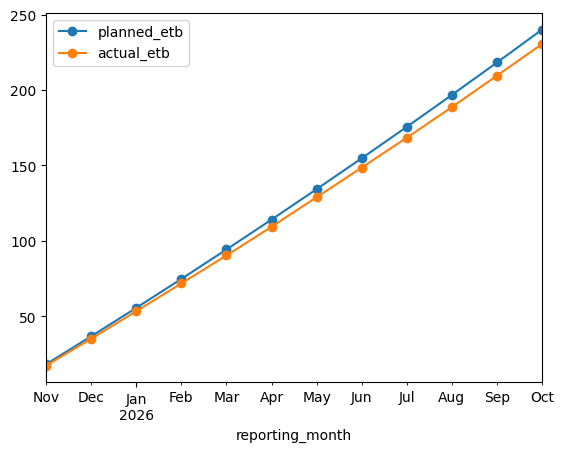

In [51]:
m = capital_project.groupby('reporting_month')[
['planned_etb', 'actual_etb']
].sum()
p = m.sort_index().cumsum() / 1e6
p.plot(marker='o')
plt.show()

In [53]:
p = inventory_movment.pivot_table(
index='warehouse',
columns='event_type',
values='transaction_id',
aggfunc='count',
fill_value=0)
print(p)
print(p.shape)
print(int(p.to_numpy().sum()))

event_type  Issued  Received  Returned  Transferred
warehouse                                          
WH-E            76        39        37           38
WH-N            75        40        39           37
WH-S            68        34        35           33
WH-W            69        31        33           36
(4, 4)
720


In [56]:
p = inventory_movment.pivot_table(
index='warehouse',
columns='material_family',
values='line_value_etb',
aggfunc='sum',
fill_value=0)
print('ETB', round(p.to_numpy().sum()))

ETB 48978275


In [54]:
p

event_type,Issued,Received,Returned,Transferred
warehouse,,,,
WH-E,76,39,37,38
WH-N,75,40,39,37
WH-S,68,34,35,33
WH-W,69,31,33,36


In [59]:
p = inventory_movment.pivot_table(
index='warehouse',
columns='material_family',
values='line_value_etb',
aggfunc='sum',
fill_value=0)
print('ETB', round(p.to_numpy().sum()))

p

ETB 48978275


material_family,Civil Material,Electrical Part,Pipe Fitting,Safety Supply,Valve Spare
warehouse,,,,,
WH-E,4937545,3471520,580785,2554745,1582075
WH-N,4448585,3599005,501290,2664230,1577045
WH-S,3893105,3725740,432730,2419970,1316955
WH-W,4179000,3002845,504695,2134030,1452380


In [61]:
p = inventory_movment.pivot_table(
index='warehouse',
columns='event_type',
values='transaction_id',
aggfunc='count',
fill_value=0,
margins=True)
print('grand total:', int(p.loc['All', 
'All']))
p

grand total: 720


event_type,Issued,Received,Returned,Transferred,All
warehouse,,,,,
WH-E,76,39,37,38,190
WH-N,75,40,39,37,191
WH-S,68,34,35,33,170
WH-W,69,31,33,36,169
All,288,144,144,144,720


In [66]:
p = fleet_trip_log.pivot_table(
index='branch',
columns='vehicle_class',
values='km_travelled',
aggfunc=['mean','sum','median'])
print(p.columns.nlevels)
print(p.shape)
p

2
(6, 12)


mean                                          sum         \
vehicle_class Light Truck Pickup Service Truck Utility Van Light Truck Pickup   
branch                                                                          
Akaki             110.125  116.2        109.25       127.2        1762   2324   
Bole              116.875   99.2         94.00       113.0        1870   1984   
Gullele            96.500  125.0        109.25       110.3        1544   2500   
Kirkos            111.750  112.8        126.25       106.2        1788   2256   
Lideta            128.750  110.8        116.00       121.8        2060   2216   
Nifas Silk        113.500  113.5        100.75        96.0        1816   2270   

                                             median                       \
vehicle_class Service Truck Utility Van Light Truck Pickup Service Truck   
branch                                                                     
Akaki                  1748        2544       115.0  122.0         111.0   
Bole                   1504        2260       112.0  105.0          94.0   
Gullele                1748        2206        93.0  115.0         104.0   
Kirkos                 2020        2124       117.0  117.0         128.0   
Lideta                 1856        2436       134.0  112.0         116.0   
Nifas Silk             1612        1920       110.0  110.0          99.0   

                           
vehicle_class Utility Van  
branch                     
Akaki               133.0  
Bole                116.0  
Gullele             111.0  
Kirkos              106.0  
Lideta              123.0  
Nifas Silk           99.0

In [65]:
p = pd.crosstab(
index=inventory_movment.warehouse,
columns=inventory_movment.event_type,
normalize='index')*100
print(p.sum(axis=1).round().to_dict())
p

{'WH-E': 100.0, 'WH-N': 100.0, 'WH-S': 100.0, 'WH-W': 100.0}


event_type,Issued,Received,Returned,Transferred
warehouse,,,,
WH-E,40.000000,20.526316,19.473684,20.000000
WH-N,39.267016,20.942408,20.418848,19.371728
WH-S,40.000000,20.000000,20.588235,19.411765
WH-W,40.828402,18.343195,19.526627,21.301775


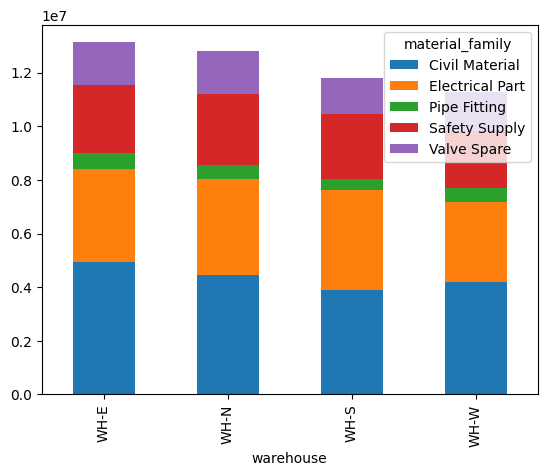

In [67]:
p = inventory_movment.pivot_table(
index='warehouse',
columns='material_family',
values='line_value_etb',
aggfunc='sum', fill_value=0)
p.plot.bar(stacked=True)
plt.show()

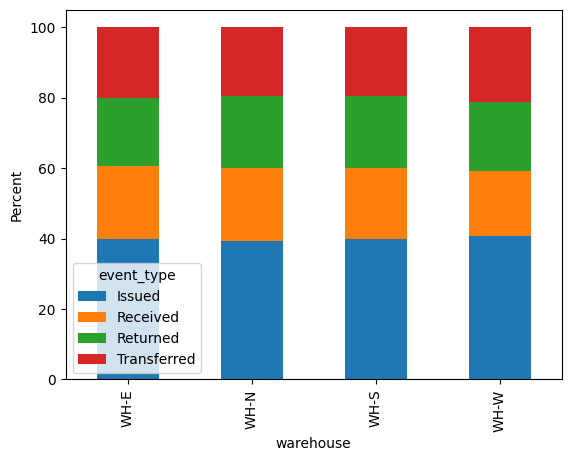

In [68]:
p= pd.crosstab(
index=inventory_movment.warehouse,
columns=inventory_movment.event_type,
normalize='index')*100
p.plot.bar(stacked=True)
plt.ylabel('Percent')
plt.show()

In [72]:
small = montly_kpi[['unit','month',
'stock_receipts']].copy()
p = small.pivot(index='month',
columns='unit',values='stock_receipts')
print(p.shape)
p

(12, 8)


unit,Unit-01,Unit-02,Unit-03,Unit-04,Unit-05,Unit-06,Unit-07,Unit-08
month,,,,,,,,
2025-11-01,70,81,92,103,114,125,136,147
2025-12-01,74,85,96,107,118,129,140,151
2026-01-01,78,89,100,111,122,133,144,155
2026-02-01,82,93,104,115,126,137,148,159
2026-03-01,86,97,108,119,130,141,152,163
2026-04-01,90,101,112,123,134,145,156,167
2026-05-01,94,105,116,127,138,149,160,171
2026-06-01,98,109,120,131,142,153,164,175
2026-07-01,102,113,124,135,146,157,168,179


In [75]:
long = montly_kpi.melt(
id_vars=['unit','month','branch'],
value_vars=['stock_receipts',
'stock_issues'],
var_name='metric',value_name='value')
print(long.shape)
long

(192, 5)


,unit,month,branch,metric,value
0,Unit-01,2025-11-01,Bole,stock_receipts,70
1,Unit-01,2025-12-01,Bole,stock_receipts,74
2,Unit-01,2026-01-01,Bole,stock_receipts,78
3,Unit-01,2026-02-01,Bole,stock_receipts,82
4,Unit-01,2026-03-01,Bole,stock_receipts,86
...,...,...,...,...,...
187,Unit-08,2026-06-01,Akaki,stock_issues,145
188,Unit-08,2026-07-01,Akaki,stock_issues,150
189,Unit-08,2026-08-01,Akaki,stock_issues,155
190,Unit-08,2026-09-01,Akaki,stock_issues,160


In [76]:
long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   unit    192 non-null    object        
 1   month   192 non-null    datetime64[ns]
 2   branch  192 non-null    object        
 3   metric  192 non-null    object        
 4   value   192 non-null    int64         
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 7.6+ KB


In [78]:
p = inventory_movment.groupby([
'warehouse','event_type']).size()
wide_counts = p.unstack(fill_value=0)
back = wide_counts.stack()
print(wide_counts.shape)
print(int(back.sum()))
p

(4, 4)
720


warehouse  event_type 
WH-E       Issued         76
           Received       39
           Returned       37
           Transferred    38
WH-N       Issued         75
           Received       40
           Returned       39
           Transferred    37
WH-S       Issued         68
           Received       34
           Returned       35
           Transferred    33
WH-W       Issued         69
           Received       31
           Returned       33
           Transferred    36
dtype: int64

In [79]:
p.shape

(16,)

In [81]:
p = inventory_movment.pivot_table(
index='warehouse',columns='event_type',
values='transaction_id',
aggfunc='count',fill_value=0)
print(p.loc['WH-N'].sum())
p

191


event_type,Issued,Received,Returned,Transferred
warehouse,,,,
WH-E,76,39,37,38
WH-N,75,40,39,37
WH-S,68,34,35,33
WH-W,69,31,33,36


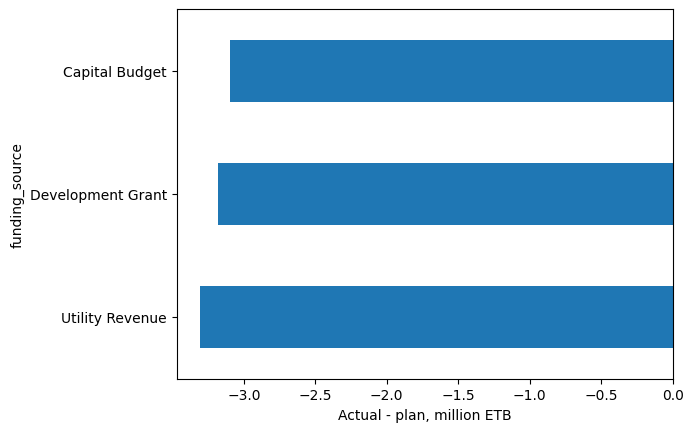

In [82]:
p = capital_project.groupby('funding_source')[
'variance_etb'].sum()/1e6
p.sort_values().plot.barh()
plt.xlabel('Actual - plan, million ETB')
plt.show()

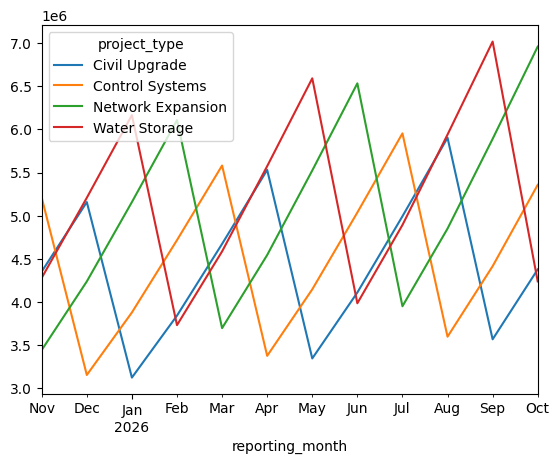

In [83]:
p = capital_project.groupby([
'reporting_month','project_type'
]).actual_etb.sum().unstack(
fill_value=0)
p.plot.line()
plt.show()

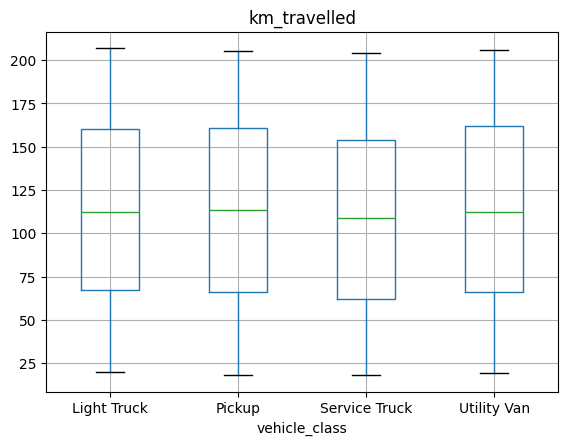

In [84]:
fleet_trip_log.boxplot(
column='km_travelled',
by='vehicle_class')
plt.suptitle('')
plt.show()

<Axes: xlabel='month'>

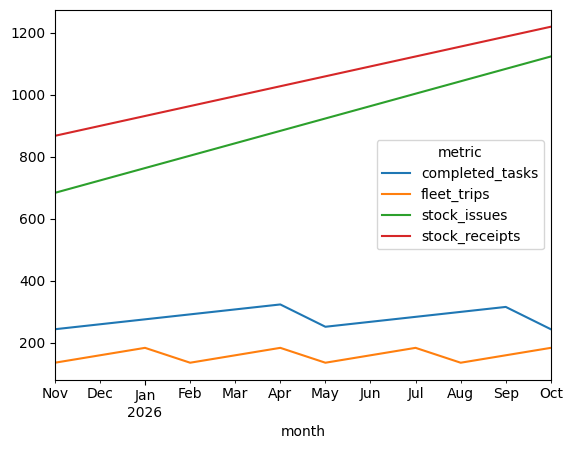

In [86]:
long = montly_kpi.melt(
id_vars=['unit','month'],
value_vars=['stock_receipts','stock_issues',
'completed_tasks','fleet_trips'],
var_name='metric',value_name='value')
p = long.groupby(['month','metric'])['value'].sum().unstack()
p.plot()

In [89]:
all_units = inventory_movment.signed_units.sum()
by_wh = inventory_movment.groupby('warehouse')['signed_units'].sum().sum()
print(all_units, by_wh)
print('match', all_units == by_wh)
all_units

-7125 -7125
match True


np.int64(-7125)